# Data Splitting and Preprocessing — Earthworm Acute Toxicity

In [ ]:
import os

## Modify and uncomment the appropiate lines below to mark the right path to the folder where all the files are going to be stored

# if you upload your files directly, decomment next line:
PATH = "/content/sample_data/"

# if you use GoogleDrive, decomment next lines (You will need to give permission to Colab to access your Drive account):
# from google.colab import drive
# drive.mount('/content/drive')
# PATH = "/content/drive/MyDrive/PQSAR_Python_Course/" # Here we added a folder name where all the data is going to be stored in the google drive

## Section 1: Open and check descriptors dataset

To use our data to build a predictive ML model, we need to obtain a training set and a test set. In our case, we will perform this split after separating the descriptors. Therefore, we require a dataframe containing the `SMILES` column, an output variable `y` column, and several columns with the descriptors.

Complete the code in the next cell to load the data from the most recently saved file in the previous lesson, and print the column names to check that it has loaded correctly.

In [ ]:
#@title Open the descriptors database and check the file

import pandas as pd
import os

file_name = 'Earthworm_acute_toxicity_descriptors_cleaned.csv'
file_path = os.path.join(PATH, file_name)

df_classification_with_descriptors = pd.read_csv(file_path)
display(df_classification_with_descriptors.head())

,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,COc1nc(C)nc(NC(=O)NS(=O)(=O)c2ccccc2OCCCl)n1,0,12.444044,12.444044,0.018077,-4.199046,0.663432,10.884615,401.832,385.704,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
1,CCO/N=C(\CC)C1=C(O)CC(c2c(C)cc(C)cc2C)CC1=O,1,12.687206,12.687206,0.020416,-0.052381,0.630443,18.958333,329.440,302.224,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
2,CC1(C(=O)Nc2ccc(O)c(Cl)c2Cl)CCCCC1,0,12.362376,12.362376,0.031614,-0.341328,0.783852,18.052632,302.201,285.065,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
3,O=C(NC(=O)c1c(F)cccc1F)Nc1cc(Cl)c(OC(F)(F)C(F)...,0,13.562079,13.562079,0.439345,-5.940878,0.476966,12.812500,511.152,503.088,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
4,O=[N+]([O-])c1cc(C(F)(F)F)c(Cl)c([N+](=O)[O-])...,0,13.024378,13.024378,0.059866,-5.268467,0.337712,12.000000,465.093,461.061,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556


## Section 2: Train/test splitting

The simplest way is to split the data randomly. Refer to the [scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) on this topic.

In our case, we will establish a proportion of 70% of the data for training and 30% for the test set.


In [ ]:
#@title First example of a random split
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df_classification_with_descriptors, test_size=0.3) #Specify the dataframe to split and the test set fraction

print('Full data shape:',df_classification_with_descriptors.shape)
print('Train shape:',df_train.shape,'Test shape:', df_test.shape)
df_test.head()

Full data shape: (124, 1665)
Train shape: (86, 1665) Test shape: (38, 1665)


,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
77,C=C1C[C@]23C[C@H]1CC[C@H]2[C@@]12CC[C@H](O)[C@...,0,12.713701,12.713701,0.087847,-1.090460,0.567611,57.500000,332.396,308.204,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
69,Nc1cc(Cl)nc(C(=O)O)c1Cl,0,10.465062,10.465062,0.008611,-1.255370,0.686254,9.833333,207.016,202.984,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
113,CCOc1cc(C(C)(C)C)ccc1C1COC(c2c(F)cccc2F)=N1,0,13.990480,13.990480,0.006531,-0.682859,0.753084,17.000000,359.416,336.232,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
45,CO/C=C(/C(=O)OC)c1ccccc1Oc1cc(Oc2ccccc2C#N)ncn1,1,12.126699,12.126699,0.183816,-0.576185,0.330013,10.633333,403.394,386.258,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
103,CC(C)N(C(=O)SCC(Cl)=C(Cl)Cl)C(C)C,1,11.874689,11.874689,0.015988,-0.015988,0.740153,10.812500,304.670,288.542,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556


After executing the previous cell correctly, you should have split the original dataframe into two dataframes with the same columns but fewer rows. Together, these two dataframes still add up to the total. You can also view the first rows in the test set.

If you execute the cell again, the number of rows should remain the same, but the specific molecules included in the test set may change.

Randomness is very useful in machine learning, as it allows us to explore different combinations without introducing bias. However, it has the drawback of producing non-reproducible results. For this reason, it is advisable to use a seed. A seed is a predefined value that the random number generator uses to produce values in a reproducible, though still complex and seemingly random, way. Any number can be chosen, as it is not expected to carry meaning or be optimised. In this case, we will use the current year as an example.

Therefore, to obtain the expected results and to ensure that you can verify your outputs in this practice module, you should use the seed value 2023 in the random split by including the argument `random_state=2023` in the `train_test_split` call.

In [ ]:
#Random split with seed = 2023

#Now copy and modify the previous cell here

print('Full data shape:',df_classification_with_descriptors.shape)
print('Train shape:', df_train.shape,'Test shape:', df_test.shape)
df_test.head()

Full data shape: (124, 1665)
Train shape: (86, 1665) Test shape: (38, 1665)


,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
77,C=C1C[C@]23C[C@H]1CC[C@H]2[C@@]12CC[C@H](O)[C@...,0,12.713701,12.713701,0.087847,-1.090460,0.567611,57.500000,332.396,308.204,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
69,Nc1cc(Cl)nc(C(=O)O)c1Cl,0,10.465062,10.465062,0.008611,-1.255370,0.686254,9.833333,207.016,202.984,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
113,CCOc1cc(C(C)(C)C)ccc1C1COC(c2c(F)cccc2F)=N1,0,13.990480,13.990480,0.006531,-0.682859,0.753084,17.000000,359.416,336.232,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
45,CO/C=C(/C(=O)OC)c1ccccc1Oc1cc(Oc2ccccc2C#N)ncn1,1,12.126699,12.126699,0.183816,-0.576185,0.330013,10.633333,403.394,386.258,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
103,CC(C)N(C(=O)SCC(Cl)=C(Cl)Cl)C(C)C,1,11.874689,11.874689,0.015988,-0.015988,0.740153,10.812500,304.670,288.542,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556


Run the next cell to check the proportions of positive and negative molecules in your training and test sets

If you look at the values in the graph, the ratio between the red blocks, which correspond to the positive values, and the green blocks is not distributed in the same way across the two sets. The numbers confirm this imbalance: the positive values are divided between the two sets, with 37 in the positive group and 21 in the negative group. However, the negative values are mostly placed in the training set, with 54 compared to 18 in the test set, which creates a noticeable difference.

This is a possible and undesirable outcome of the random split. Instead of using a simple random split, more advanced techniques can be applied, such as the clustering approach described in the video. Another option is to adjust the random split so that it takes into account the distribution of the endpoint.

To achieve this, copy the code for the previous split below, including the random state, and add an extra parameter to the `train_test_split` function: `stratify`. In this case, we want the algorithm to preserve the distribution of the y column, so the correct parameter is `stratify=df_classification_with_descriptors['y']`.


In [ ]:
#@title Random split stratified with seed 2023

df_train, df_test = train_test_split(df_classification_with_descriptors, test_size=0.3, random_state=2023)

print('Full data shape:',df_classification_with_descriptors.shape)
print('Train shape:',df_train.shape,'Test shape:', df_test.shape)
df_test.head()

Full data shape: (124, 1665)
Train shape: (86, 1665) Test shape: (38, 1665)


,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
89,Cc1cc(O)no1,1,8.448194,8.448194,0.057870,-0.057870,0.520055,9.285714,99.089,94.049,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
114,Nc1c(Cl)c(Cl)nc(C(=O)O)c1Cl,0,10.533278,10.533278,0.044753,-1.309938,0.739877,10.076923,241.461,238.437,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
9,Oc1nc2ccc(Cl)cc2nc1O,0,9.041478,9.041478,0.447037,-0.490957,0.673127,10.538462,196.593,191.553,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
97,COc1c(Cl)ccc(Cl)c1C(=O)O,0,10.730617,10.730617,0.084877,-1.162639,0.834381,9.769231,221.039,214.991,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556
30,CCCOc1nc2ccc(I)cc2c(=O)n1CCC,0,12.494212,12.494212,0.017158,-0.017158,0.757631,10.894737,372.206,355.070,...,10.239281,81.589367,383.200905,7.096313,2271,42,148.0,171.0,10.8125,5.930556


In [ ]:
first_smiles_in_test_set = df_test['SMILES'].iloc[0]
print(first_smiles_in_test_set)

Cc1cc(O)no1


###**Q1.** Which is the SMILES of the first molecule in your test set?
Please enter the SMILES into the platform before proceeding.

Use the cell below to plot the new distribution of positive and negative values.

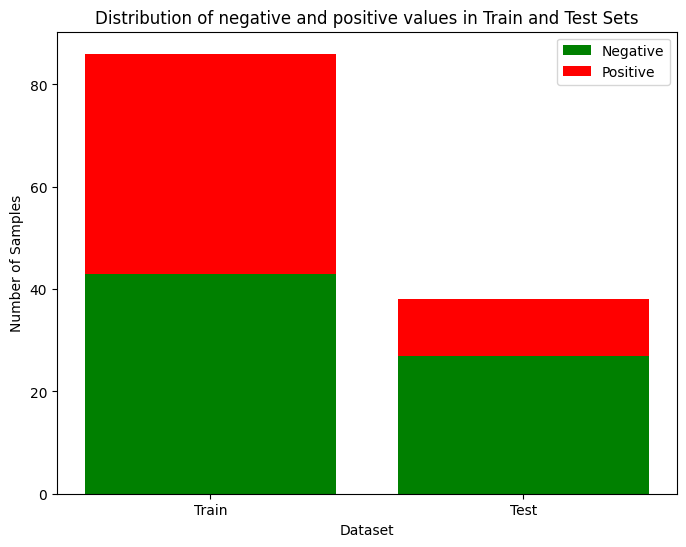

Train. Positives: 43  Negatives: 43  Ratio: 1.0
Test. Positives: 11  Negatives: 27  Ratio: 0.4074074074074074


In [ ]:
#@title Visualise the distribution of values
%matplotlib inline

import matplotlib.pyplot as plt
import pandas as pd # Ensure pandas is imported

# Define mapping for classification values, making it case-insensitive
def map_toxicity(value):
    val_lower = str(value).lower()
    if 'non-toxic' in val_lower or 'negative' in val_lower:
        return 0  # Negative class
    elif 'positive' in val_lower or 'toxic' in val_lower:
        return 1  # Positive class
    return None # Handle unexpected values if any, otherwise this won't be hit

# Apply the mapping to create a new 'y' column in copies of the dataframes
# This ensures the original df_train and df_test are not modified in place
df_train_plot = df_train.copy()
df_test_plot = df_test.copy()

# The 'y' column already contains the correct numerical classification (0 or 1),
# so re-applying map_toxicity or looking for a 'value' column is not necessary.
# The problematic lines df_train_plot['y'] = df_train_plot['value'].apply(map_toxicity)
# and df_test_plot['y'] = df_test_plot['value'].apply(map_toxicity) have been removed.

# Calculate the counts of 1 and 0 in the training and test sets
train_value_counts = df_train_plot['y'].value_counts()
test_value_counts = df_test_plot['y'].value_counts()

# Create a stacked bar plot
categories = ['Train', 'Test']

# Use .get() with a default of 0 to safely access counts, in case a class is missing in a split
negative_count_train = train_value_counts.get(0, 0)
positive_count_train = train_value_counts.get(1, 0)
negative_count_test = test_value_counts.get(0, 0)
positive_count_test = test_value_counts.get(1, 0)

negative_value_counts = [negative_count_train, negative_count_test]
positive_value_counts = [positive_count_train, positive_count_test]

# Plot each individual Series
plt.figure(figsize=(8, 6)) # Added figure size for better readability
plt.bar(categories, negative_value_counts, label='Negative', color='green')
plt.bar(categories, positive_value_counts, bottom=negative_value_counts, label='Positive', color='red')
# Add labels, a title, and a legend
plt.xlabel('Dataset')
plt.ylabel('Number of Samples')
plt.title('Distribution of negative and positive values in Train and Test Sets')
plt.legend()
plt.show() # Explicitly show the plot

dic = {"Train": df_train_plot['y'].value_counts(ascending=True),
       "Test": df_test_plot['y'].value_counts(ascending=True)}

# Handle potential division by zero for ratio calculation
ratio_train = positive_count_train / negative_count_train if negative_count_train != 0 else float('inf')
ratio_test = positive_count_test / negative_count_test if negative_count_test != 0 else float('inf')

print('Train. Positives:', positive_count_train,' Negatives:', negative_count_train,' Ratio:', ratio_train)
print('Test. Positives:', positive_count_test,' Negatives:', negative_count_test,' Ratio:', ratio_test)


The proportions in both columns should now be more similar, which is important for a reliable assessment of the model. In addition, the training set is more balanced. Ideally, the training set should be balanced to avoid introducing bias into the model, even though some machine learning algorithms can manage this imbalance.

Run the next cell to save the training and test sets into two CSV files, which will be used in the following parts. Make sure you save these files, as you will need them later in this module.

In [ ]:
#@title Save the subsets as CSV files.
## WRITE YOUR CODE HERE
df_train.to_csv(PATH + 'Earthworm_acute_toxicity_Train.csv', index=False)
df_test.to_csv(PATH + 'Earthworm_acute_toxicity_Test.csv', index=False)

## Section 3: Imputation of the descriptors matrix

The machine learning algorithms that we use in QSAR are designed to work with numerical descriptors to represent chemical structure. We therefore need to ensure that all descriptor values are numerical and meaningful. To achieve this, we will perform a process called imputation. Imputation identifies null values and replaces them with the average of the values from the three most similar molecules in the training dataset that contain a valid value for the descriptor.

In the following cell, we will prepare a function that carries out the imputation along with a few preparatory steps. This function:

* requires two inputs: the table of descriptors to be imputed and the table of descriptors from the training set used to find the similar molecules

* selects only the descriptor columns

* converts all values to the same numeric type, specifically `float64`

* instantiates a `KNNImputer` object with the appropriate parameters

* fits the `KNNImputer` with the training data

* transforms the non-valid values in the target dataset

* returns only the transformed dataset

In [ ]:
#@title Function for imputation
from sklearn.impute import KNNImputer #https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html
import numpy as np
import pandas as pd
def imputation(target_df,train_df,desc_columns):
    ''' Function to perform the imputation in a dataframe of descriptors,
        requires two datasets: the one to be imputated and the one used to inform the imputation (it can be the same)'''

    # Instantiate the imputer with the KNNImputer class
    imputer = KNNImputer(missing_values=np.nan, n_neighbors=3, weights="uniform")

    # Fit the imputer with the descriptor columns in the training DataFrame
    imputer.fit(train_df[desc_columns])
    # Transform the data using the descriptor columns in the target DataFrame
    result = imputer.transform(target_df[desc_columns])

    # KNNImputer returns a NumPy array, so we need to convert it back to a DataFrame
    # Convert the result to a DataFrame, including the result and the column names separately
    imputed_df = pd.DataFrame(result, columns=desc_columns)

    #This DataFrame only includes descriptors, so insert the SMILES and y columns back from the original DataFrame
    imputed_df = pd.concat([target_df[['SMILES', 'y']].reset_index(drop=True), imputed_df.reset_index(drop=True)], axis=1)

    return imputed_df

Apply the function above to the training and test sets obtained from the split. Note that the function only transforms the descriptors, so it is not necessary to remove additional columns such as `SMILES` or `y` from the input DataFrames. The function filters them automatically, but they will not be included in the results. You will therefore need to concatenate the output of the imputer with the `SMILES` and `y` columns.


In [ ]:
#@title Apply the imputer
# Rename 'value' column to 'y' in all relevant dataframes
if 'value' in df_classification_with_descriptors.columns:
    df_classification_with_descriptors = df_classification_with_descriptors.rename(columns={'value': 'y'})
if 'value' in df_train.columns:
    df_train = df_train.rename(columns={'value': 'y'})
if 'value' in df_test.columns:
    df_test = df_test.rename(columns={'value': 'y'})

# Extract the list of descriptors as a variable
desc_columns = df_classification_with_descriptors.drop(columns=['SMILES', 'y']).columns

# Apply the function imputation_prediction to df_train and df_test
df_train_imputed = imputation(df_train,df_train,desc_columns)
df_test_imputed = imputation(df_test,df_train,desc_columns)

In [ ]:
#@title Standardisation of the training set

# Import the library
from sklearn.preprocessing import StandardScaler
# Instantiate the scaler using the StandardScaler class
scaler = StandardScaler()

# Fit to the training data
scaler.fit(df_train_imputed[desc_columns])
# Transform the training and testing data
train_scaled = scaler.transform(df_train_imputed[desc_columns])

# As with imputation, the scaler transformation returns a NumPy array. Let’s check
print(type(train_scaled))

# Convert it back to a DataFrame and concatenate it with the SMILES and y columns from the original DataFrame

df_train_imputed_scaled = pd.DataFrame(train_scaled, columns = list(desc_columns))
smiles_train = list(df_train_imputed['SMILES'])
y_train = list(df_train_imputed['y'])

df_train_imputed_scaled.insert(0,'SMILES',smiles_train)
df_train_imputed_scaled.insert(1,'y',y_train)

# Apply the transformation to the test DataFrame and insert the SMILES and y columns
test_scaled = scaler.transform(df_test_imputed[desc_columns])

df_test_imputed_scaled = pd.DataFrame(test_scaled, columns=list(desc_columns))
smiles_test = list(df_test_imputed['SMILES'])
y_test = list(df_test_imputed['y'])

df_test_imputed_scaled.insert(0, 'SMILES', smiles_test)
df_test_imputed_scaled.insert(1, 'y', y_test)

# Insert your code here to visualise the DataFrame and check the result
display(df_train_imputed_scaled.head())

<class 'numpy.ndarray'>


,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,CCCc1cc(=O)[nH]c(=S)[nH]1,1,-0.228088,-0.228088,-0.356370,0.891711,0.045771,-0.627098,-1.672444,-1.655258,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
1,c1ccc(CNc2ncnc3[nH]cnc23)cc1,0,-2.768083,-2.768083,2.459976,1.330501,0.381869,-0.549745,-1.121324,-1.094976,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
2,Cc1c(F)cc(C(=O)NC2CC2)cc1-c1ccc(C(=O)NCC(C)(C)...,1,1.124221,1.124221,-0.891063,0.724365,1.034446,-0.173354,0.463498,0.389414,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
3,CCOP(=S)(OCC)SCn1c(=O)oc2cc(Cl)ccc21,1,0.182414,0.182414,0.509075,-0.305236,0.186973,-0.372676,0.306721,0.342079,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
4,OC(Cn1cncn1)(c1ccc(F)cc1)c1ccccc1F,0,1.052710,1.052710,-0.761426,0.085969,0.925125,-0.187036,-0.359616,-0.327065,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0


###**Q2.1** Which are the values of the `AATS7Z` descriptor for the molecule with SMILES 'CN1CSC(=S)N(C)C1' before and after imputation?

To answer question Q2 in the platform, you need to combine it with question Q2.2 after scaling.

You can view the value for a particular molecule by filtering your DataFrame for the rows where the value of `SMILES` is equal to `CN1CSC(=S)N(C)C1`.

In [ ]:
target_smiles = 'CN1CSC(=S)N(C)C1'
descriptor = 'AATS7Z'

# Value before imputation (from original dataframe)
value_before_imputation = df_classification_with_descriptors[df_classification_with_descriptors['SMILES'] == target_smiles][descriptor].iloc[0]
print(f"Value before imputation for {descriptor}: {value_before_imputation}")

# Value after imputation
# Check if the molecule is in the train or test set
if target_smiles in df_train_imputed['SMILES'].values:
    value_after_imputation = df_train_imputed[df_train_imputed['SMILES'] == target_smiles][descriptor].iloc[0]
    print(f"Value after imputation (Train Set) for {descriptor}: {value_after_imputation}")
elif target_smiles in df_test_imputed['SMILES'].values:
    value_after_imputation = df_test_imputed[df_test_imputed['SMILES'] == target_smiles][descriptor].iloc[0]
    print(f"Value after imputation (Test Set) for {descriptor}: {value_after_imputation}")
else:
    print(f"Molecule with SMILES '{target_smiles}' not found in either imputed training or test sets.")

Value before imputation for AATS7Z: 15.245454545454546
Value after imputation (Train Set) for AATS7Z: 15.245454545454546


In [ ]:
df_test_imputed["AATS7Z"].isna().sum()

np.int64(0)

For safety, and in case you want to check the imputation results, we recommend saving your datasets as CSV files. For example, you can name them:
* Earthworm_acute_toxicity_Train_imputed.csv
* Earthworm_acute_toxicity_Test_imputed.csv

## Section 4: Scaling the descriptors matrix

Some machine learning algorithms are very sensitive to feature scaling and can be strongly influenced by features that vary in larger ranges than others. This is why feature scaling is an important step in building a machine learning model.

Refer to the information on scikit-learn’s [StandardScaler function](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). Use it to transform your descriptors so that they are all on the same scale.

In [ ]:
#@title Save your DataFrames
df_train_imputed.to_csv(PATH + 'Earthworm_acute_toxicity_Train_imputed.csv', index=False)
df_test_imputed.to_csv(PATH + 'Earthworm_acute_toxicity_Test_imputed.csv', index=False)
df_train_imputed_scaled.to_csv(PATH + 'Earthworm_acute_toxicity_Train_imputed_scaled.csv', index=False)
df_test_imputed_scaled.to_csv(PATH + 'Earthworm_acute_toxicity_Test_imputed_scaled.csv', index=False)

In [ ]:
#@title Standardisation of the training set

# Import the library
from sklearn.preprocessing import StandardScaler
# Instantiate the scaler using the StandardScaler class
scaler = StandardScaler()

# Fit to the training data
scaler.fit(df_train_imputed[desc_columns])
# Transform the training and testing data
train_scaled = scaler.transform(df_train_imputed[desc_columns])

# As with imputation, the scaler transformation returns a NumPy array. Let’s check
print(type(train_scaled))

# Convert it back to a DataFrame and concatenate it with the SMILES and y columns from the original DataFrame

df_train_imputed_scaled = pd.DataFrame(train_scaled, columns = list(desc_columns))
smiles_train = list(df_train_imputed['SMILES'])
y_train = list(df_train_imputed['y'])

df_train_imputed_scaled.insert(0,'SMILES',smiles_train)
df_train_imputed_scaled.insert(1,'y',y_train)

# Apply the transformation to the test DataFrame and insert the SMILES and y columns
test_scaled = scaler.transform(df_test_imputed[desc_columns])

df_test_imputed_scaled = pd.DataFrame(test_scaled, columns=list(desc_columns))
smiles_test = list(df_test_imputed['SMILES'])
y_test = list(df_test_imputed['y'])

df_test_imputed_scaled.insert(0, 'SMILES', smiles_test)
df_test_imputed_scaled.insert(1, 'y', y_test)

# Insert your code here to visualise the DataFrame and check the result
display(df_train_imputed_scaled.head())

<class 'numpy.ndarray'>


,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,CCCc1cc(=O)[nH]c(=S)[nH]1,1,-0.228088,-0.228088,-0.356370,0.891711,0.045771,-0.627098,-1.672444,-1.655258,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
1,c1ccc(CNc2ncnc3[nH]cnc23)cc1,0,-2.768083,-2.768083,2.459976,1.330501,0.381869,-0.549745,-1.121324,-1.094976,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
2,Cc1c(F)cc(C(=O)NC2CC2)cc1-c1ccc(C(=O)NCC(C)(C)...,1,1.124221,1.124221,-0.891063,0.724365,1.034446,-0.173354,0.463498,0.389414,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
3,CCOP(=S)(OCC)SCn1c(=O)oc2cc(Cl)ccc21,1,0.182414,0.182414,0.509075,-0.305236,0.186973,-0.372676,0.306721,0.342079,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0
4,OC(Cn1cncn1)(c1ccc(F)cc1)c1ccccc1F,0,1.052710,1.052710,-0.761426,0.085969,0.925125,-0.187036,-0.359616,-0.327065,...,-1.776357e-15,2.842171e-14,5.684342e-14,-8.881784e-16,0.0,0.0,0.0,0.0,0.0,0.0


Save the scaled versions of both the training and test datasets so they are ready to use in the following lesson. We recommend using the following names:
*   Earthworm_acute_toxicity_Train_imputed_scaled.csv
*   Earthworm_acute_toxicity_Test_imputed_scaled.csv



###**Q2.2** Which is the value of the `AATS7Z` descriptor for the molecule with SMILES 'CN1CSC(=S)N(C)C1' after standardization?

Combine this value with your response to question Q2.1 above to complete the test in the platform.

In [ ]:
target_smiles = 'CN1CSC(=S)N(C)C1'
descriptor = 'AATS7Z'

# Value before imputation (from original dataframe)
original_value = df_classification_with_descriptors[df_classification_with_descriptors['SMILES'] == target_smiles][descriptor].iloc[0]

# Value after imputation (from imputed training set, as the molecule was found there)
imputed_value = df_train_imputed[df_train_imputed['SMILES'] == target_smiles][descriptor].iloc[0]

# Value after scaling (from scaled training set)
scaled_value = df_train_imputed_scaled[df_train_imputed_scaled['SMILES'] == target_smiles][descriptor].iloc[0]

print(f"SMILES: {target_smiles}")
print(f"Descriptor: {descriptor}")
print(f"Original value: {original_value}")
print(f"Imputed value: {imputed_value}")
print(f"Scaled value: {scaled_value}")

SMILES: CN1CSC(=S)N(C)C1
Descriptor: AATS7Z
Original value: 15.245454545454546
Imputed value: 15.245454545454546
Scaled value: -1.7763568394002505e-15


### Min-Max Scaler

There are alternative methods of scaling. Another common one is the `MinMaxScaler`, which fits the values into a range between 0 and 1 by default. You can try it here if you wish, but to avoid confusion in later steps of this module, do not save the values scaled with min–max.

Here is the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) for reference.

In [ ]:
#@title Min–max scaling of the training set

# Import the library
from sklearn.preprocessing import MinMaxScaler


# Read the imputed descriptors of the training set from the saved CSV file.
# This step is not required if you already have the DataFrame in memory, but it is a good way to double-check that nothing has changed
df_train_imputed = pd.read_csv(PATH + 'Earthworm_acute_toxicity_Train_imputed.csv')
desc_columns = [col for col in df_train_imputed.columns if col not in ['SMILES', 'y']]

# Instantiate the scaler using the MinMaxScaler class
mm_scaler = MinMaxScaler()

# Fit to the training data
mm_scaler.fit(df_train_imputed[desc_columns])
# Transform the training and testing data
train_mmscaled = mm_scaler.transform(df_train_imputed[desc_columns])


# Convert it back to a DataFrame and concatenate it with the SMILES and y columns from the original DataFrame

df_train_mmscaled = pd.DataFrame(train_mmscaled, columns = list(desc_columns))

df_train_imputed_mmscaled = pd.concat([df_train_imputed[['SMILES','y']],df_train_mmscaled],axis=1)

df_train_imputed_mmscaled

,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,CCCc1cc(=O)[nH]c(=S)[nH]1,1,0.511780,0.511780,0.117342,0.841895,0.609942,0.021626,0.016766,0.017908,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,c1ccc(CNc2ncnc3[nH]cnc23)cc1,0,0.000000,0.000000,0.664115,0.964941,0.687268,0.035588,0.132737,0.139505,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Cc1c(F)cc(C(=O)NC2CC2)cc1-c1ccc(C(=O)NCC(C)(C)...,1,0.784256,0.784256,0.013535,0.794968,0.837406,0.103524,0.466229,0.461660,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,CCOP(=S)(OCC)SCn1c(=O)oc2cc(Cl)ccc21,1,0.594492,0.594492,0.285362,0.506246,0.642428,0.067548,0.433238,0.451387,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,OC(Cn1cncn1)(c1ccc(F)cc1)c1ccccc1F,0,0.769847,0.769847,0.038703,0.615948,0.812255,0.101055,0.293022,0.306164,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,Nc1c([N+](=O)[O-])ccc(Oc2ccccc2)c1Cl,1,0.498397,0.498397,0.032391,0.774961,0.420568,0.024637,0.215815,0.232777,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
82,COC(=O)CC(NC(=O)[C@@H](NC(=O)OC(C)C)C(C)C)c1cc...,0,0.659693,0.659693,0.046403,0.742195,0.605508,0.085930,0.498732,0.494107,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
83,COc1cc(OC)n2nc(NS(=O)(=O)c3c(C(F)(F)F)ccnc3OC)...,0,0.703157,0.703157,0.089183,0.138960,0.544240,0.066029,0.573496,0.605733,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
84,N#Cc1sc2c(=O)c3ccccc3c(=O)c=2sc1C#N,1,0.631002,0.631002,0.150541,0.821813,0.578826,0.029662,0.282559,0.315412,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


You can use the code below to visualise the effect of the different scalers and how they modify the values. Change the names of the descriptors in the cell to check new descriptors.

In the second graph, the distribution of the scaled values for two descriptors is shown using both methods. To view the original descriptors, uncomment the relevant line in the code. Depending on the descriptor, visualising the scaled values may be difficult because the scale of the graph will change.

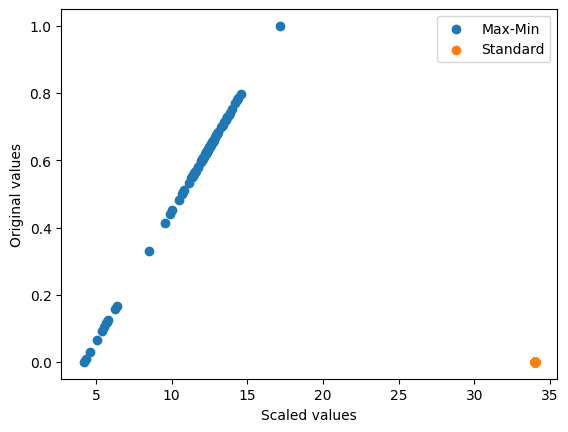

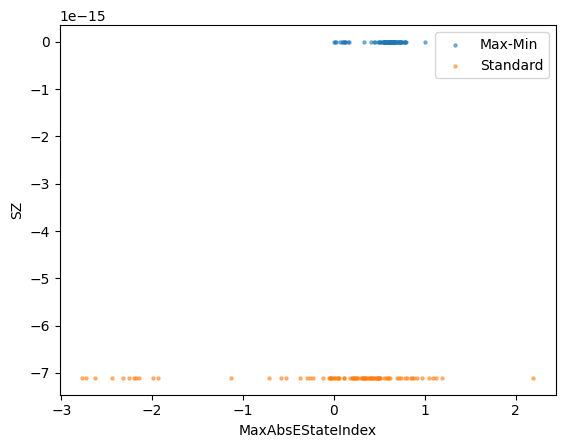

In [ ]:
#@title Visualise the scaling
%matplotlib inline

import matplotlib.pyplot as plt

descriptor1='MaxAbsEStateIndex'
descriptor2='SZ'

original1=list(df_train_imputed[descriptor1])
maxmin1=list(df_train_imputed_mmscaled[descriptor1])
standard1=list(df_train_imputed_scaled[descriptor1])


original2=list(df_train_imputed[descriptor2])
maxmin2=list(df_train_imputed_mmscaled[descriptor2])
standard2=list(df_train_imputed_scaled[descriptor2])

#fig, ((ax1,ax2),(ax3,ax4)) = plt.subplots(2,2,figsize = (10, 10))
#fig, (ax1,ax2) = plt.subplots(1,2,figsize = (10, 4))
plt.figure(0)
plt.scatter(original1,maxmin1,label='Max-Min')
plt.scatter(original2,standard2,label='Standard')
plt.xlabel('Scaled values')
plt.ylabel('Original values')
plt.legend()

plt.figure(1)
#plt.scatter(original1,original2,label='original',s=5,alpha=0.5) #Uncomment this to see the original
plt.scatter(maxmin1,maxmin2,label='Max-Min',s=5,alpha=0.5)
plt.scatter(standard1,standard2,label='Standard',s=5,alpha=0.5)
plt.xlabel(descriptor1)
plt.ylabel(descriptor2)
plt.legend()

